In [1]:
import os
os.environ["ARROW_USER_SIMD_LEVEL"] = "NONE"

import json, time, hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import sklearn
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
)

SEED = 42
ART = os.path.expanduser("~/mlproject/artifacts")
METRICS_DIR = os.path.expanduser("~/mlproject/metrics")
os.makedirs(METRICS_DIR, exist_ok=True)

vectorizer = joblib.load(f"{ART}/lab2_span_tfidf.joblib")
model      = joblib.load(f"{ART}/lab2_span_logreg.joblib")

df_te = pd.read_parquet(f"{ART}/test.parquet")
df_tr = pd.read_parquet(f"{ART}/train.parquet")

print("sklearn:", sklearn.__version__)
print("test rows:", len(df_te))

sklearn: 1.9.1
test rows: 532


In [2]:
def flatten_spans(df):
    rows = []
    for _, r in df.iterrows():
        text = r["text"] or ""
        starts = r["entity_starts"]
        if starts is None:
            continue
        try:
            if len(starts) == 0:
                continue
        except TypeError:
            continue
        for s, e, l in zip(r["entity_starts"], r["entity_ends"], r["entity_labels"]):
            rows.append({"span": text[s:e], "label": l, "start": s, "end": e})
    return pd.DataFrame(rows)

sp_te = flatten_spans(df_te)
print(f"спанов в test: {len(sp_te)}")
print(sp_te["label"].value_counts().head(10))

X_te = vectorizer.transform(sp_te["span"])
y_te = sp_te["label"].values

y_pred = model.predict(X_te)
y_proba = model.predict_proba(X_te)
classes = model.classes_

print(f"предсказано: {len(y_pred)}")

спанов в test: 3159
label
ip                579
name              300
first_name        285
date              241
address_city      232
last_name         203
mobile_phone      195
address           180
address_street    151
organization      116
Name: count, dtype: int64
предсказано: 3159


In [3]:
metrics = {
    "accuracy":        float(accuracy_score(y_te, y_pred)),
    "precision_macro": float(precision_score(y_te, y_pred, average="macro", zero_division=0)),
    "recall_macro":    float(recall_score(y_te, y_pred, average="macro", zero_division=0)),
    "f1_macro":        float(f1_score(y_te, y_pred, average="macro", zero_division=0)),
    "f1_weighted":     float(f1_score(y_te, y_pred, average="weighted", zero_division=0)),
}
for k, v in metrics.items():
    print(f"{k:>16}: {v:.4f}")

report_dict = classification_report(
    y_te, y_pred, output_dict=True, zero_division=0
)
# per-class метрики (только реальные классы, без avg-строк)
per_class = {
    cls: {
        "precision": float(report_dict[cls]["precision"]),
        "recall":    float(report_dict[cls]["recall"]),
        "f1":        float(report_dict[cls]["f1-score"]),
        "support":   int(report_dict[cls]["support"]),
    }
    for cls in classes if cls in report_dict
}

print("\n--- Per-class (первые 10) ---")
for cls, m in list(per_class.items())[:10]:
    print(f"{cls:<25} P={m['precision']:.3f} R={m['recall']:.3f} "
          f"F1={m['f1']:.3f} n={m['support']}")

        accuracy: 0.8088
 precision_macro: 0.6117
    recall_macro: 0.6844
        f1_macro: 0.6306
     f1_weighted: 0.8157

--- Per-class (первые 10) ---
address                   P=0.827 R=0.506 F1=0.628 n=180
address_apartment         P=0.091 R=0.200 F1=0.125 n=5
address_building          P=0.000 R=0.000 F1=0.000 n=0
address_city              P=0.719 R=0.716 F1=0.717 n=232
address_country           P=0.346 R=0.818 F1=0.486 n=11
address_district          P=0.294 R=0.455 F1=0.357 n=22
address_geolocation       P=0.900 R=1.000 F1=0.947 n=45
address_house             P=0.730 R=0.730 F1=0.730 n=63
address_postal_code       P=0.000 R=0.000 F1=0.000 n=6
address_region            P=0.500 R=0.750 F1=0.600 n=20


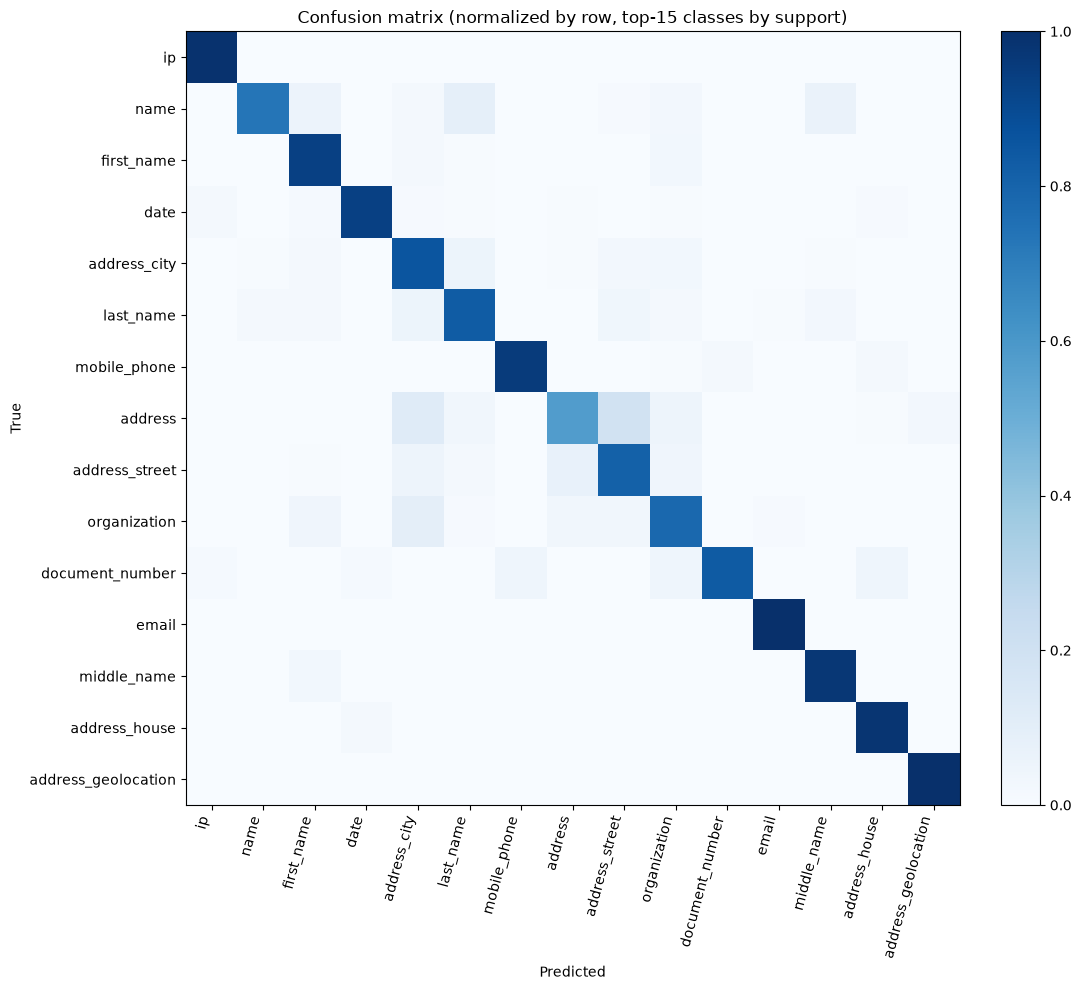

Сохранено: /home/mluser/mlproject/metrics/confusion_matrix.png


In [4]:
# top-15 классов по support в test — чтобы heatmap читался
top = (sp_te["label"].value_counts().head(15).index.tolist())
mask = sp_te["label"].isin(top).values
cm = confusion_matrix(y_te[mask], y_pred[mask], labels=top)

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
cm_norm = np.nan_to_num(cm_norm)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=75, ha="right")
ax.set_yticks(range(len(top))); ax.set_yticklabels(top)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Confusion matrix (normalized by row, top-15 classes by support)")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(f"{METRICS_DIR}/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Сохранено: {METRICS_DIR}/confusion_matrix.png")

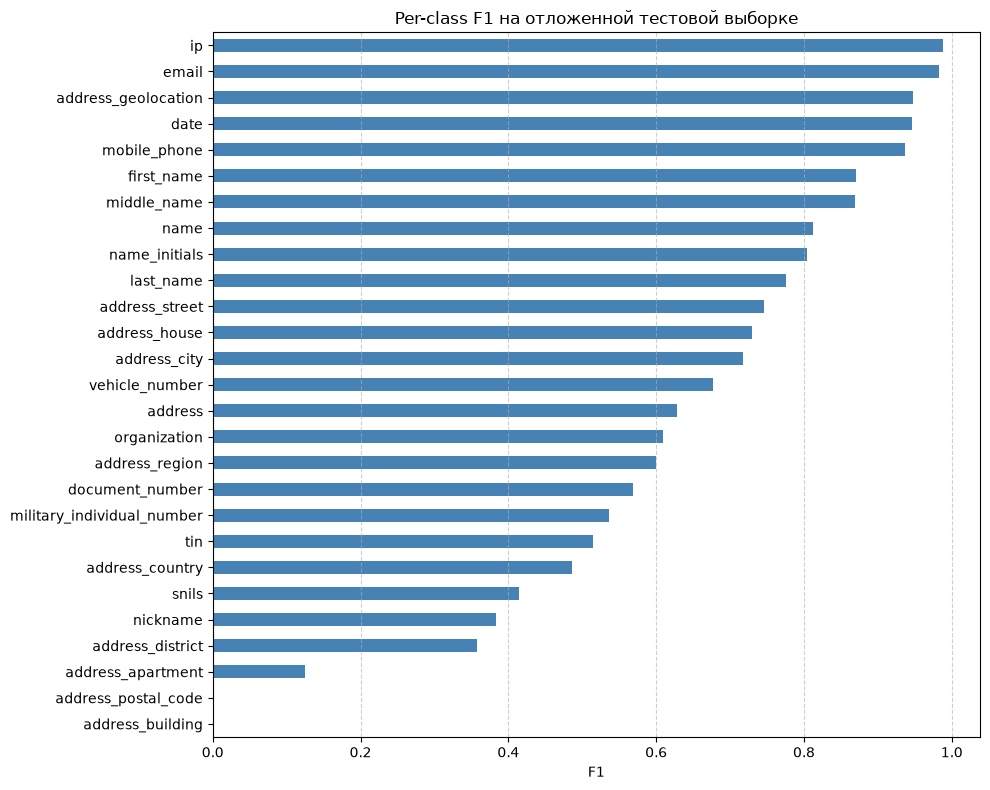

In [5]:
pc = pd.Series({c: m["f1"] for c, m in per_class.items()}).sort_values()
plt.figure(figsize=(10, 8))
pc.plot(kind="barh", color="steelblue")
plt.xlabel("F1")
plt.title("Per-class F1 на отложенной тестовой выборке")
plt.grid(axis="x", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(f"{METRICS_DIR}/per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# 6.1 Топ-10 пар (true → pred), где true != pred
err = pd.DataFrame({"true": y_te, "pred": y_pred, "span": sp_te["span"].values})
confused = (err[err["true"] != err["pred"]]
            .groupby(["true", "pred"]).size()
            .sort_values(ascending=False).head(10))
print("--- Топ-10 перепутанных пар (true → pred) ---")
print(confused)

# 6.2 Несколько конкретных ошибок с confidence
proba_max = y_proba.max(axis=1)
proba_pred_idx = y_proba.argmax(axis=1)
err_df = pd.DataFrame({
    "span": sp_te["span"].values,
    "true": y_te,
    "pred": y_pred,
    "confidence": proba_max,
})
wrong = err_df[err_df["true"] != err_df["pred"]].copy()
wrong = wrong.sort_values("confidence", ascending=False).head(10)

print("\n--- 10 уверенных ошибок (true != pred) ---")
for _, r in wrong.iterrows():
    print(f"  span={r['span']!r:<40} true={r['true']:<20} "
          f"pred={r['pred']:<20} conf={r['confidence']:.2f}")

--- Топ-10 перепутанных пар (true → pred) ---
true             pred          
address          address_street    30
address_city     nickname          26
name             last_name         25
address          address_city      19
name             middle_name       18
document_number  tin               18
name             first_name        16
organization     nickname          13
document_number  snils             12
name             name_initials     12
dtype: int64

--- 10 уверенных ошибок (true != pred) ---
  span='48.4020, 35.0430'                       true=address              pred=address_geolocation  conf=0.98
  span='Київської області, из городка Вишнёвое' true=address              pred=address_region       conf=0.93
  span='ул. Литейной'                           true=address              pred=address_street       conf=0.91
  span='23 кв2'                                 true=date                 pred=address_apartment    conf=0.90
  span='В.'                                  

In [7]:
# baseline: самый частый класс в train
def flatten(df):
    rows = []
    for _, r in df.iterrows():
        t = r["text"] or ""
        s = r["entity_starts"]
        if s is None: continue
        try:
            if len(s) == 0: continue
        except TypeError: continue
        for st, en, lb in zip(r["entity_starts"], r["entity_ends"], r["entity_labels"]):
            rows.append(lb)
    return rows

train_labels = flatten(df_tr)
majority = pd.Series(train_labels).value_counts().idxmax()
baseline_pred = np.full(len(y_te), majority)
baseline = {
    "majority_class": majority,
    "accuracy": float(accuracy_score(y_te, baseline_pred)),
    "f1_macro": float(f1_score(y_te, baseline_pred, average="macro", zero_division=0)),
}

# идентификатор версии данных
SNAPSHOT = "6af0587dde068d90d8a1080285159c374b46a09b"
checksums_path = os.path.expanduser("~/mlproject/data/CHECKSUMS.sha256")
test_arrow_sha = None
with open(checksums_path) as f:
    for line in f:
        h, name = line.split(maxsplit=1)
        if name.strip().endswith("test.arrow"):
            test_arrow_sha = h
            break

print("baseline:", baseline)
print("test.arrow sha256:", test_arrow_sha)

baseline: {'majority_class': 'ip', 'accuracy': 0.18328584995251662, 'f1_macro': 0.011915051240893938}
test.arrow sha256: b83e61317f398e6c0cabbd2428c7e52251a7b688a197735128d507437c3e8e4b


In [8]:
payload = {
    "lab": "LR2",
    "task": "span-type classification (baseline component for NER)",
    "evaluation_split": "test (hold-out, not used for tuning)",
    "main_metric": {
        "name": "macro_f1",
        "value": metrics["f1_macro"],
        "rationale": "дисбаланс 27 типов; macro-F1 штрафует провал по редким классам, "
                     "weighted-F1 и accuracy маскируют его",
    },
    "metrics": metrics,
    "baseline_majority": baseline,
    "test_size_spans": int(len(y_te)),
    "n_classes": int(len(classes)),
    "data_version": {
        "dataset": "scanpatch/pii-ner-corpus-synthetic-controlled",
        "snapshot_hash": SNAPSHOT,
        "test_arrow_sha256": test_arrow_sha,
    },
    "model": {
        "type": "LogisticRegression(class_weight='balanced', max_iter=1000)",
        "vectorizer": "TfidfVectorizer(analyzer='char_wb', ngram_range=(2,5), "
                      "max_features=10000, min_df=1)",
        "seed": SEED,
        "sklearn_version": sklearn.__version__,
    },
    "per_class": per_class,
    "top_confusions": [
        {"true": t, "pred": p, "count": int(c)}
        for (t, p), c in confused.items()
    ],
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
}

out = f"{METRICS_DIR}/baseline.json"
with open(out, "w") as f:
    json.dump(payload, f, indent=2, ensure_ascii=False)

print(f"Сохранено: {out}")
print(json.dumps({k: payload[k] for k in
                  ("main_metric", "test_size_spans", "data_version")},
                 indent=2, ensure_ascii=False))

Сохранено: /home/mluser/mlproject/metrics/baseline.json
{
  "main_metric": {
    "name": "macro_f1",
    "value": 0.6306346060388888,
    "rationale": "дисбаланс 27 типов; macro-F1 штрафует провал по редким классам, weighted-F1 и accuracy маскируют его"
  },
  "test_size_spans": 3159,
  "data_version": {
    "dataset": "scanpatch/pii-ner-corpus-synthetic-controlled",
    "snapshot_hash": "6af0587dde068d90d8a1080285159c374b46a09b",
    "test_arrow_sha256": "b83e61317f398e6c0cabbd2428c7e52251a7b688a197735128d507437c3e8e4b"
  }
}
